### ML App (Credit Card Fraud Detection System) Part 3

#### Team members

- Alson Garbuja
- Kapil Bam
- Slok Baniya
- Nishan Parajuli
- Karma Dolma Gurung
- Sishir Kharel

In [1]:
"""
Imports

This cell has all the required imports from the third party libraries like pandas, numpy and sckit-learn (sklearn)
"""

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

In [2]:
"""
Data pre-processing

This cell contains the data pre-processing and cleaning of the data for the model to be fed
"""

df = pd.read_csv('datasets/creditcard.csv')
df.dropna()

X_reg = df.drop(['Amount', 'Time', 'Class'], axis=1)
y_reg = df['Amount']

X_cls = df.drop(['Class', 'Time'], axis=1)
y_cls = df['Class']

In [3]:
"""
Data splitting

This cell uses the train_test_split function from sklearn package to split the dataset into training and testing sets.

The `stratify = y_cls` argument makes sure the extreme 99% to 1% normal to fraud data distribution in the original dataset is maintained 
in both training and testing splits of the data.
"""

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls, y_cls, test_size=0.2, random_state=42, stratify=y_cls
)

In [4]:
"""
Data scaling

This cell holds the code to scale the data with mean of 0 and standard deviation of 1 so that numerically larger data doesnot dominate the
smaller data.
"""

scaler_reg = StandardScaler()
X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

scaler_cls = StandardScaler()
X_train_cls_scaled = scaler_cls.fit_transform(X_train_cls)
X_test_cls_scaled = scaler_cls.transform(X_test_cls)

=== DIMENSIONALITY REDUCTION (PCA) ===


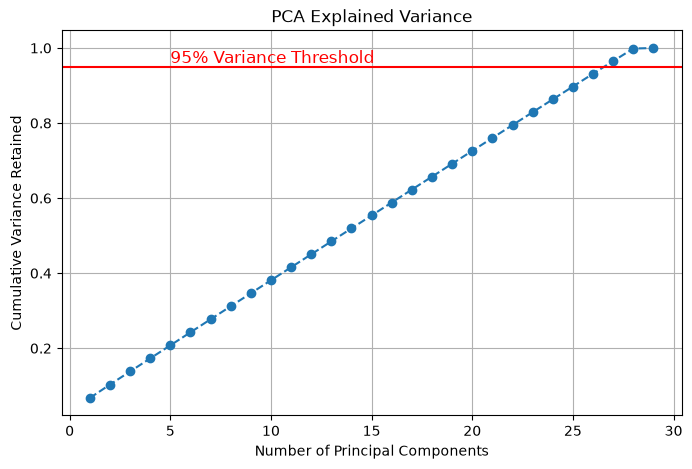

Original Features: 29
Reduced Features (PCA): 27
Total Variance Retained: 0.97



In [5]:
from sklearn.decomposition import PCA
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

print("=== DIMENSIONALITY REDUCTION (PCA) ===")

pca = PCA().fit(X_train_cls_scaled)

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.axhline(y=0.95, color='r', linestyle='-')
plt.text(5, 0.96, '95% Variance Threshold', color='red', fontsize=12)
plt.title('PCA Explained Variance')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Variance Retained')
plt.grid(True)
plt.show()

pca_optimal = PCA(n_components=0.95, random_state=42)
X_train_pca = pca_optimal.fit_transform(X_train_cls_scaled)
X_test_pca = pca_optimal.transform(X_test_cls_scaled)

print(f"Original Features: {X_train_cls_scaled.shape[1]}")
print(f"Reduced Features (PCA): {X_train_pca.shape[1]}")
print(f"Total Variance Retained: {np.sum(pca_optimal.explained_variance_ratio_):.2f}\n")

In [6]:
print("=== HYPERPARAMETER TUNING (Random Forest) ===")

param_grid = {
    'n_estimators': [50, 100],         # Number of trees in the forest
    'max_depth': [10, 20, None],       # Maximum depth of each tree
    'min_samples_split': [2, 5],       # Minimum samples required to split an internal node
    'class_weight': ['balanced', {0: 1, 1: 10}] # Testing automatic balance vs custom penalty
}

rf_base = RandomForestClassifier(random_state=42, n_jobs=-1)

grid_search = GridSearchCV(
    estimator=rf_base, 
    param_grid=param_grid, 
    cv=3,                 # 3-fold cross-validation
    scoring='f1_macro',   # Optimize for the balance of precision and recall across both classes
    n_jobs=-1,
    verbose=2
)

# Fit the grid search on the PCA-reduced data
grid_search.fit(X_train_pca, y_train_cls)

print("\n--- Tuning Results ---")
print(f"Best Hyperparameters: {grid_search.best_params_}")

=== HYPERPARAMETER TUNING (Random Forest) ===
Fitting 3 folds for each of 24 candidates, totalling 72 fits

--- Tuning Results ---
Best Hyperparameters: {'class_weight': 'balanced', 'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 50}



=== OPTIMIZED MODEL EVALUATION ===
--- Optimized Random Forest Report ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.85      0.73      0.79        98

    accuracy                           1.00     56962
   macro avg       0.92      0.87      0.89     56962
weighted avg       1.00      1.00      1.00     56962



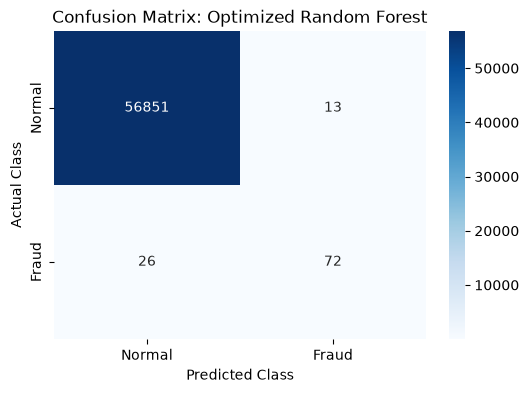

In [7]:
print("\n=== OPTIMIZED MODEL EVALUATION ===")

best_rf_model = grid_search.best_estimator_

y_pred_optimized = best_rf_model.predict(X_test_pca)

print("--- Optimized Random Forest Report ---")
print(classification_report(y_test_cls, y_pred_optimized))

cm = confusion_matrix(y_test_cls, y_pred_optimized)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Fraud'], yticklabels=['Normal', 'Fraud'])
plt.title('Confusion Matrix: Optimized Random Forest')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.show()